In [1]:
import glob, os, re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

SIZE_ORDER = ['XS', 'S', 'M', 'L', 'XL']

TOKEN_COLS = [
    'judge_input_tokens', 'judge_output_tokens',
    'auditor_input_tokens', 'auditor_output_tokens',
    'target_input_tokens', 'target_output_tokens',
]
TOKEN_LABELS = {
    'judge_input_tokens':    'Judge Input',
    'judge_output_tokens':   'Judge Output',
    'auditor_input_tokens':  'Auditor Input',
    'auditor_output_tokens': 'Auditor Output',
    'target_input_tokens':   'Target Input',
    'target_output_tokens':  'Target Output',
}
TOKEN_COLORS = {
    'judge_input_tokens':    '#1f77b4',
    'judge_output_tokens':   '#aec7e8',
    'auditor_input_tokens':  '#d62728',
    'auditor_output_tokens': '#f7b6b6',
    'target_input_tokens':   '#2ca02c',
    'target_output_tokens':  '#98df8a',
}

In [2]:
# ── Load all petri token_usage.csv files ────────────────────────────────────
DATA_ROOT = 'petri_comparison_results'

dfs = []
for path in glob.glob(os.path.join(DATA_ROOT, '**', 'token_usage.csv'), recursive=True):
    # path: .../T=S__A=XL/J=L/token_usage.csv
    parts = path.replace('\\', '/').split('/')
    j_part  = parts[-2]   # e.g. J=L
    ta_part = parts[-3]   # e.g. T=S__A=XL
    scenario = parts[-4]  # e.g. norwegian_safety

    m_ta = re.match(r'T=(.+?)__A=(.+)', ta_part)
    m_j  = re.match(r'J=(.+)', j_part)
    if not (m_ta and m_j):
        continue
    target, auditor, judge = m_ta.group(1), m_ta.group(2), m_j.group(1)

    df = pd.read_csv(path)
    df['target']   = target
    df['auditor']  = auditor
    df['judge']    = judge
    df['scenario'] = scenario
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)
print(f'Loaded {len(df_all)} rows from {len(dfs)} files')
print('Targets: ', sorted(df_all['target'].unique()))
print('Auditors:', sorted(df_all['auditor'].unique()))
print('Judges:  ', sorted(df_all['judge'].unique()))

Loaded 290 rows from 29 files
Targets:  ['M', 'M_UNSAFE', 'S', 'S_UNSAFE', 'XS', 'XS_UNSAFE']
Auditors: ['L', 'M', 'XL']
Judges:   ['L', 'M', 'XL']


In [3]:
# ── Filter ──────────────────────────────────────────────────────────────────
# Use df_full as the working dataset — modify these lines to subset:
#
#   XL only:
# df_full = df_all[df_all['judge'].isin(['XL'])].copy()
# df_full = df_all[df_all['auditor'].isin(['XL'])].copy()
#
#   Exclude XL:
df_full = df_all[~df_all['judge'].isin(['XL'])].copy()
df_full = df_full[~df_full['auditor'].isin(['XL'])].copy()
#
# Default: all rows
# df_full = df_all.copy()

# Drop rows where all token cols are NaN (incomplete runs)
df_full = df_full.dropna(subset=TOKEN_COLS, how='all')
print(f'Working dataset: {len(df_full)} rows')

Working dataset: 230 rows


In [4]:
mask = df_full['judge_reasoning_tokens'] != 0
print(f"Rows where auditor_reasoning_tokens != 0: {mask.sum()}")
df_full[mask]

Rows where auditor_reasoning_tokens != 0: 0


,run,auditor_input_tokens,auditor_output_tokens,auditor_total_tokens,auditor_cache_read_tokens,auditor_cache_write_tokens,auditor_reasoning_tokens,target_input_tokens,target_output_tokens,target_total_tokens,...,judge_input_tokens,judge_output_tokens,judge_total_tokens,judge_cache_read_tokens,judge_cache_write_tokens,judge_reasoning_tokens,target,auditor,judge,scenario


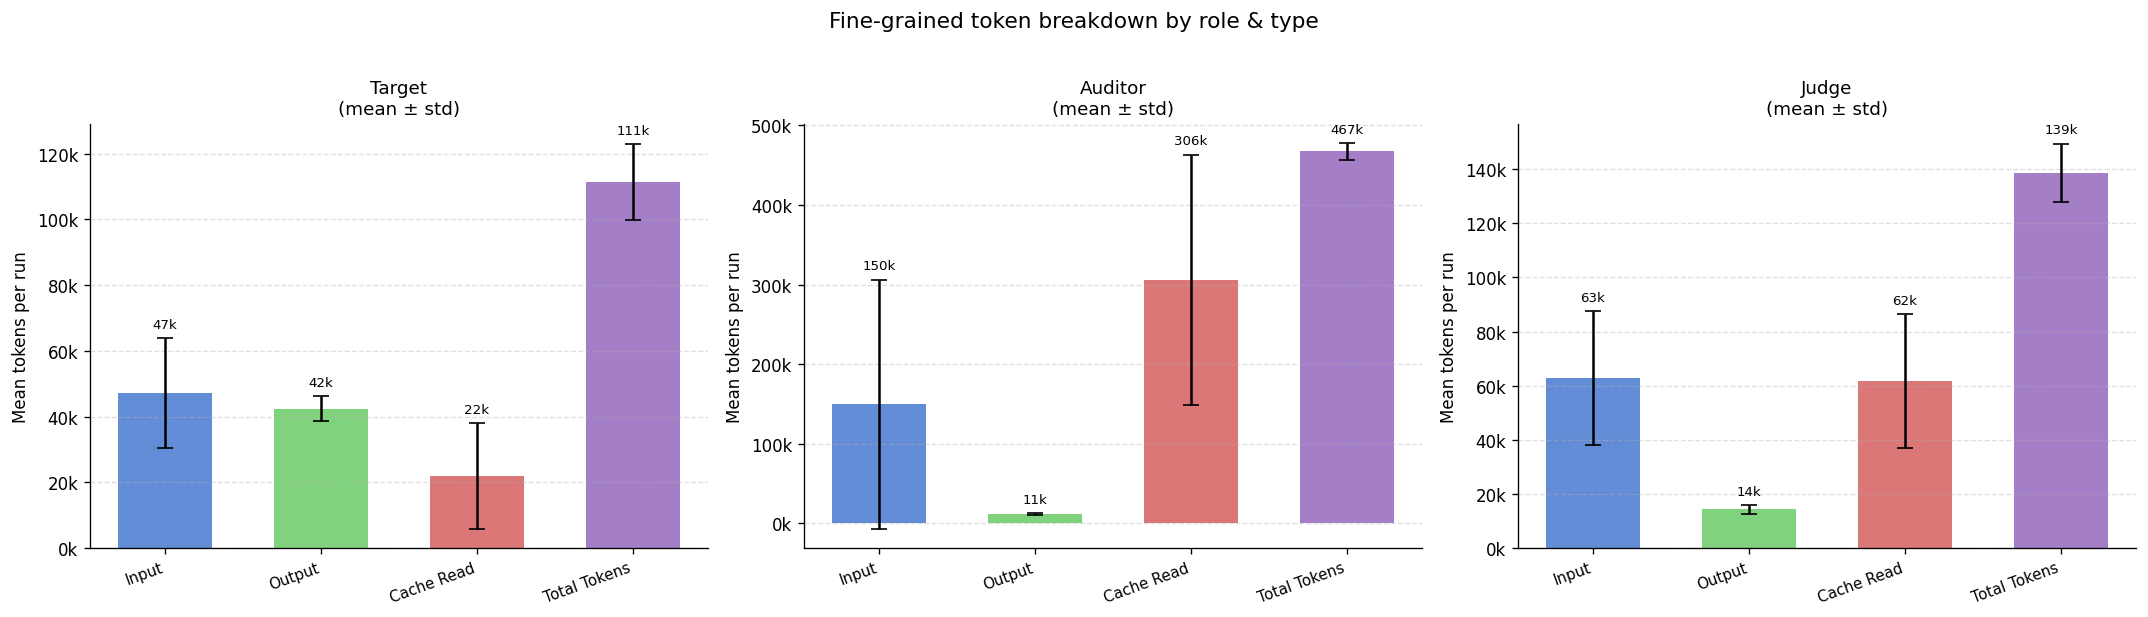


Token type                           Mean        Std

  Target
  ------------------------------------------------
  Input                            47,143     16,661
  Output                           42,415      3,837
  Cache Read                       21,861     16,073
  Total Tokens                    111,419     11,551

  Auditor
  ------------------------------------------------
  Input                           149,792    156,483
  Output                           11,497      1,258
  Cache Read                      305,789    157,086
  Total Tokens                    467,078     10,532

  Judge
  ------------------------------------------------
  Input                            62,801     24,679
  Output                           14,269      1,590
  Cache Read                       61,573     24,762
  Total Tokens                    138,643     10,658


In [5]:
# ── Fine-grained: all token types per role ───────────────────────────────────
# For each role: input, output, cache_read, cache_write, reasoning
FINE_TYPES  = ['input', 'output', 'cache_read', 'cache_write', 'reasoning', "total"]
FINE_LABELS = ['Input', 'Output', 'Cache Read', 'Cache Write', 'Reasoning', 'Total Tokens']
FINE_COLORS = ['#4878CF', '#6ACC65', '#D65F5F', '#B47CC7', '#C4AD66', '#9467BD']

roles_keys = ['target', 'auditor', 'judge']
roles_disp = ['Target', 'Auditor', 'Judge']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

for ax, role_key, role_disp in zip(axes, roles_keys, roles_disp):
    cols = [f'{role_key}_{t}_tokens' for t in FINE_TYPES]
    # only include columns that exist and have non-zero data
    present = [(c, lbl, col) for c, lbl, col in zip(cols, FINE_LABELS, FINE_COLORS)
               if c in df_full.columns and df_full[c].sum() > 0]
    if not present:
        ax.set_visible(False)
        continue
    pcols, plabels, pcolors = zip(*present)

    m_vals = [df_full[c].mean() for c in pcols]
    s_vals = [df_full[c].std()  for c in pcols]
    x      = np.arange(len(pcols))

    ax.bar(x, m_vals, 0.6, yerr=s_vals, capsize=5,
           color=pcolors, alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for xi, (m, s) in enumerate(zip(m_vals, s_vals)):
        ax.text(xi, m + s + max(m_vals) * 0.02,
                f'{m/1000:.0f}k', ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(plabels, fontsize=9, rotation=20, ha='right')
    ax.set_title(f'{role_disp}\n(mean ± std)', fontsize=11)
    ax.set_ylabel('Mean tokens per run', fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Fine-grained token breakdown by role & type', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Numerical table
print(f'\n{"Token type":<30} {"Mean":>10} {"Std":>10}')
for role_key, role_disp in zip(roles_keys, roles_disp):
    print(f'\n  {role_disp}')
    print('  ' + '-' * 48)
    for t, lbl in zip(FINE_TYPES, FINE_LABELS):
        c = f'{role_key}_{t}_tokens'
        if c not in df_full.columns or df_full[c].sum() == 0:
            continue
        m, s = df_full[c].mean(), df_full[c].std()
        print(f'  {lbl:<28} {m:>10,.0f} {s:>10,.0f}')

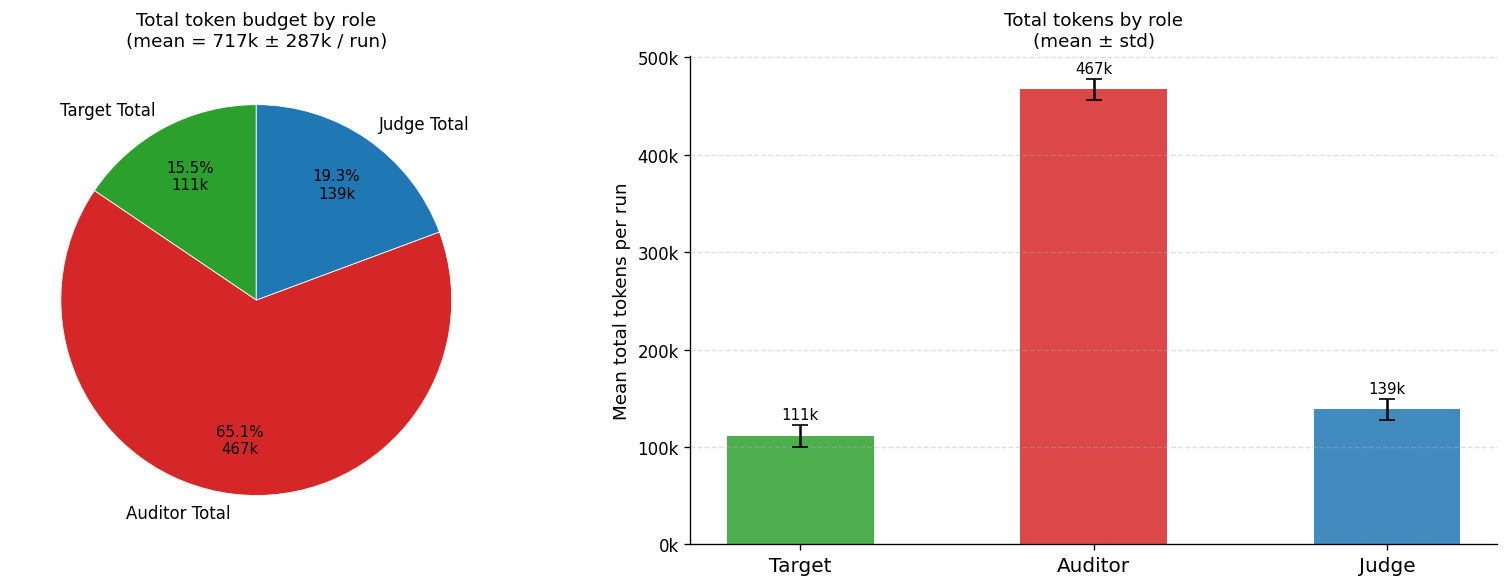


Role                   Mean total        Std   % of grand total
---------------------------------------------------------------
Target Total              111,419     11,551              15.5%
Auditor Total             467,078     10,532              65.1%
Judge Total               138,643     10,658              19.3%
---------------------------------------------------------------
GRAND TOTAL               717,140


In [6]:
# ── Total tokens only: pie + bar ─────────────────────────────────────────────
TOTAL_COLS   = ['target_total_tokens', 'auditor_total_tokens', 'judge_total_tokens']
TOTAL_LABELS = ['Target Total', 'Auditor Total', 'Judge Total']
TOTAL_COLORS = ['#2ca02c', '#d62728', '#1f77b4']
roles        = ['Target', 'Auditor', 'Judge']

tot_m  = [df_full[c].mean() for c in TOTAL_COLS]
tot_s  = [df_full[c].std()  for c in TOTAL_COLS]
grand  = sum(tot_m)
grand_std = df_full[TOTAL_COLS].sum(axis=1).std()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Pie
def make_autopct(values):
    def autopct(pct):
        val = pct / 100. * sum(values)
        return f'{pct:.1f}%\n{val/1000:.0f}k' if pct >= 4 else ''
    return autopct

wedges, texts, autotexts = axes[0].pie(
    tot_m,
    labels      = TOTAL_LABELS,
    colors      = TOTAL_COLORS,
    autopct     = make_autopct(tot_m),
    startangle  = 90, pctdistance=0.72,
    wedgeprops  = dict(linewidth=0.5, edgecolor='white')
)
for t in autotexts:
    t.set_fontsize(9)
axes[0].set_title(f'Total token budget by role\n'
                  f'(mean = {grand/1000:.0f}k ± {grand_std/1000:.0f}k / run)', fontsize=11)

# Right: bar
x  = np.arange(3)
ax = axes[1]
ax.bar(x, tot_m, 0.5, yerr=tot_s, capsize=5,
       color=TOTAL_COLORS, alpha=0.85,
       error_kw=dict(elinewidth=1.5))
for i, (m, s) in enumerate(zip(tot_m, tot_s)):
    ax.text(i, m + s + 3000, f'{m/1000:.0f}k', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(roles, fontsize=12)
ax.set_ylabel('Mean total tokens per run', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax.set_title('Total tokens by role\n(mean ± std)', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Numerical table
print(f'\n{"Role":<20} {"Mean total":>12} {"Std":>10} {"% of grand total":>18}')
print('-' * 63)
for lbl, c, m, s in zip(TOTAL_LABELS, TOTAL_COLS, tot_m, tot_s):
    print(f'{lbl:<20} {m:>12,.0f} {s:>10,.0f} {100*m/grand:>17.1f}%')
print('-' * 63)
print(f'{"GRAND TOTAL":<20} {grand:>12,.0f}')

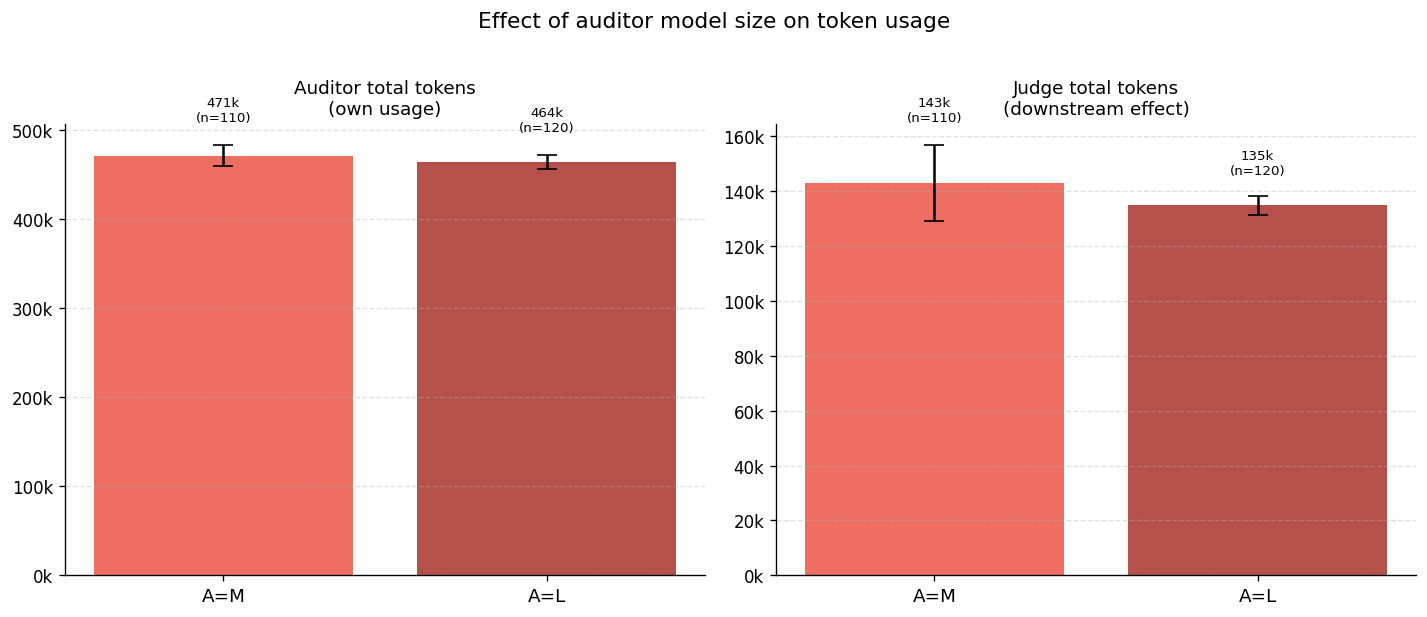

In [7]:
# ── Auditor size: own total tokens AND downstream judge total ────────────────
a_levels = [l for l in SIZE_ORDER if l in df_full['auditor'].unique()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, title in [
    (axes[0], 'auditor_total_tokens', 'Auditor total tokens\n(own usage)'),
    (axes[1], 'judge_total_tokens',   'Judge total tokens\n(downstream effect)'),
]:
    ms = [df_full[df_full['auditor'] == a][col].mean() for a in a_levels]
    ss = [df_full[df_full['auditor'] == a][col].std()  for a in a_levels]
    ns = [len(df_full[df_full['auditor'] == a])         for a in a_levels]

    bar_colors = sns.color_palette('Reds_d', len(a_levels))
    xs = np.arange(len(a_levels))
    ax.bar(xs, ms, yerr=ss, capsize=6, color=bar_colors, alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for i, (m, s, n) in enumerate(zip(ms, ss, ns)):
        if not np.isnan(m):
            top = m + (s or 0)
            ax.text(i, top + top * 0.05, f'{m/1000:.0f}k\n(n={n})',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f'A={a}' for a in a_levels], fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set_title(title, fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Effect of auditor model size on token usage', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

ml  = df_full[df_full['auditor'] == 'L' ]['auditor_total_tokens'].mean()
mxl = df_full[df_full['auditor'] == 'XL']['auditor_total_tokens'].mean()
if not (np.isnan(ml) or np.isnan(mxl)):
    print(f'A=XL uses {mxl/ml:.1f}× more total tokens than A=L')

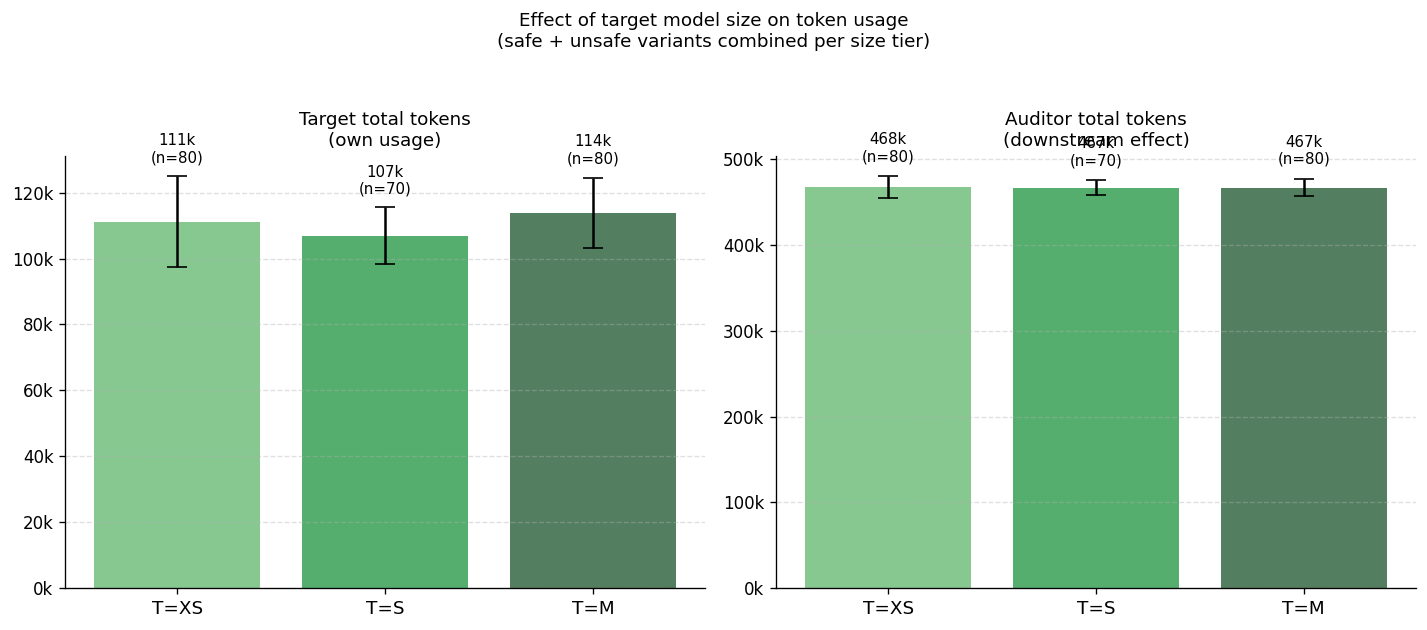

In [8]:
# ── Target size: own total tokens AND downstream auditor total ───────────────
# Strip _UNSAFE suffix so XS, XS_UNSAFE etc. are grouped by base tier
df_full['target_base'] = df_full['target'].str.replace('_UNSAFE', '', regex=False)
t_levels = [l for l in SIZE_ORDER if l in df_full['target_base'].unique()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, title in [
    (axes[0], 'target_total_tokens',  'Target total tokens\n(own usage)'),
    (axes[1], 'auditor_total_tokens', 'Auditor total tokens\n(downstream effect)'),
]:
    ms = [df_full[df_full['target_base'] == t][col].mean() for t in t_levels]
    ss = [df_full[df_full['target_base'] == t][col].std()  for t in t_levels]
    ns = [len(df_full[df_full['target_base'] == t])         for t in t_levels]

    xs = np.arange(len(t_levels))
    ax.bar(xs, ms, yerr=ss, capsize=6,
           color=sns.color_palette('Greens_d', len(t_levels)), alpha=0.85,
           error_kw=dict(elinewidth=1.5))
    for i, (m, s, n) in enumerate(zip(ms, ss, ns)):
        if not np.isnan(m):
            ax.text(i, m + (s or 0) + m * 0.03, f'{m/1000:.0f}k\n(n={n})',
                    ha='center', va='bottom', fontsize=9)
    ax.set_xticks(xs)
    ax.set_xticklabels([f'T={t}' for t in t_levels], fontsize=11)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set_title(title, fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Effect of target model size on token usage\n'
             '(safe + unsafe variants combined per size tier)', fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

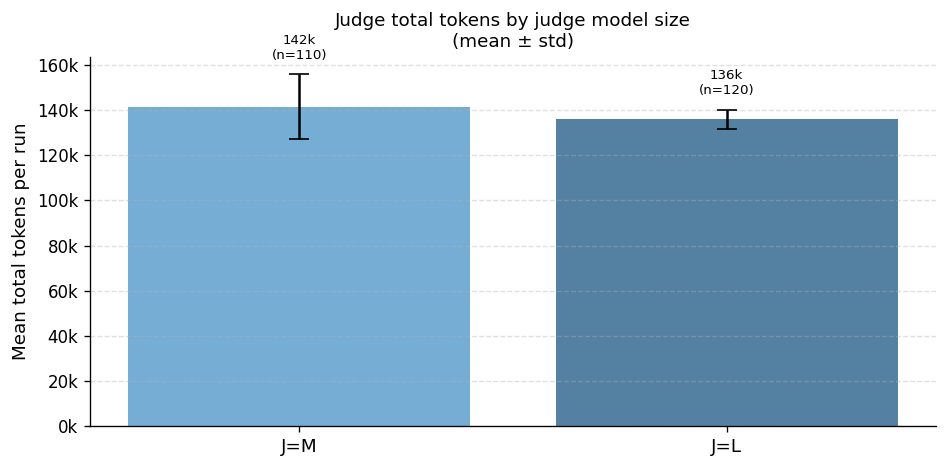

J=M: auditor distribution — {'L': np.int64(60), 'M': np.int64(50)}
J=L: auditor distribution — {'L': np.int64(60), 'M': np.int64(60)}


In [9]:
# ── Judge size → judge total tokens ─────────────────────────────────────────
j_levels = [l for l in SIZE_ORDER if l in df_full['judge'].unique()]

fig, ax = plt.subplots(figsize=(8, 4))

ms = [df_full[df_full['judge'] == j]['judge_total_tokens'].mean() for j in j_levels]
ss = [df_full[df_full['judge'] == j]['judge_total_tokens'].std()  for j in j_levels]
ns = [len(df_full[df_full['judge'] == j])                          for j in j_levels]

xs = np.arange(len(j_levels))
ax.bar(xs, ms, yerr=ss, capsize=6,
       color=sns.color_palette('Blues_d', len(j_levels)), alpha=0.85,
       error_kw=dict(elinewidth=1.5))
for i, (m, s, n) in enumerate(zip(ms, ss, ns)):
    if not np.isnan(m):
        ax.text(i, m + (s or 0) + m * 0.04, f'{m/1000:.0f}k\n(n={n})',
                ha='center', va='bottom', fontsize=8)

ax.set_xticks(xs)
ax.set_xticklabels([f'J={j}' for j in j_levels], fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax.set_title('Judge total tokens by judge model size\n(mean ± std)', fontsize=11)
ax.set_ylabel('Mean total tokens per run', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

for j in j_levels:
    combos = df_full[df_full['judge'] == j]['auditor'].value_counts()
    print(f'J={j}: auditor distribution — {dict(combos)}')